# Sales by Weekday and Month

I compare daily totals, weekday averages and monthly averages across all stores.

## 1. Load the data

Each sales row is one product in one store. The calendar maps `d_` columns to dates.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sales_path = "data/raw/sales_train_validation.csv"
calendar_path = "data/raw/calendar.csv"

sales = pd.read_csv(sales_path)
calendar = pd.read_csv(calendar_path)
day_columns = [column for column in sales.columns if column.startswith("d_")]

print(f"Sales rows: {sales.shape[0]:,}")
print(f"Days available: {len(day_columns):,}")

Sales rows: 30,490
Days available: 1,913


## 2. Daily totals

Sum units across products and stores for each sales day.

In [2]:
daily_sales = sales[day_columns].sum(axis=0).rename("units_sold").reset_index()
daily_sales = daily_sales.rename(columns={"index": "d"})
daily_sales = daily_sales.merge(calendar[["d", "date", "weekday", "month", "year"]], on="d", how="left")
daily_sales["date"] = pd.to_datetime(daily_sales["date"])
daily_sales.head()

,d,units_sold,date,weekday,month,year
0,d_1,32631,2011-01-29,Saturday,1,2011
1,d_2,31749,2011-01-30,Sunday,1,2011
2,d_3,23783,2011-01-31,Monday,1,2011
3,d_4,25412,2011-02-01,Tuesday,2,2011
4,d_5,19146,2011-02-02,Wednesday,2,2011


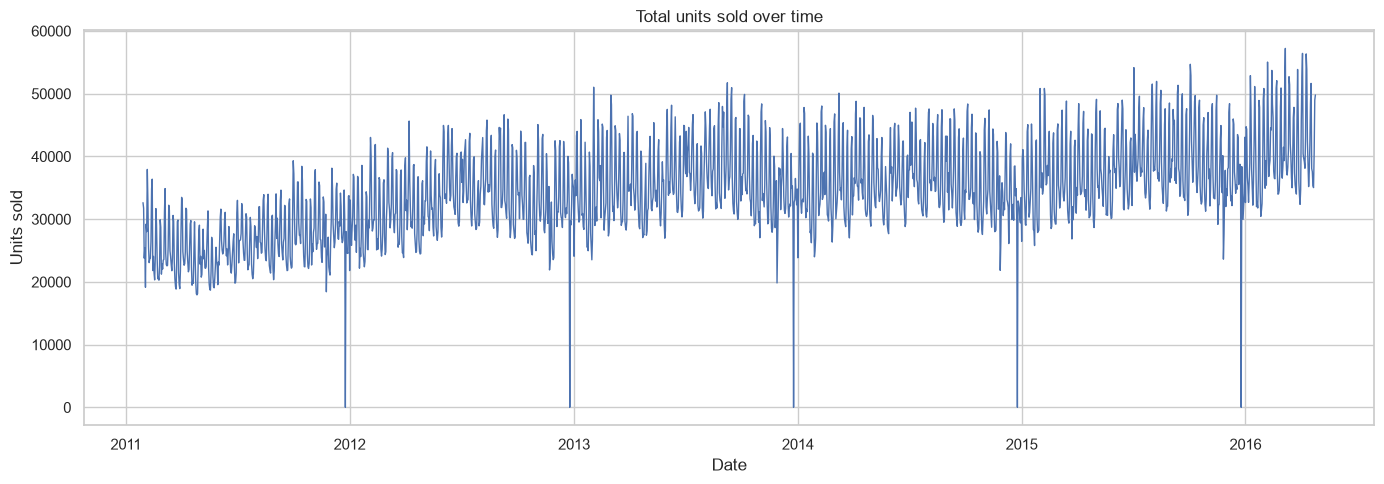

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["units_sold"], linewidth=1)
plt.title("Total units sold over time")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()

The total varies from day to day. Aggregating all stores hides differences between individual products and locations.

## 3. Weekday averages

Compare average units sold on each weekday over the full observed period.

In [4]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = (
    daily_sales.groupby("weekday", as_index=False)["units_sold"]
    .mean()
    .assign(weekday=lambda frame: pd.Categorical(frame["weekday"], categories=weekday_order, ordered=True))
    .sort_values("weekday")
)
weekday_summary

,weekday,units_sold
1,Monday,32852.967033
5,Tuesday,30368.780220
6,Wednesday,30010.021978
4,Thursday,30205.007326
0,Friday,34225.985348
2,Saturday,41546.894161
3,Sunday,41130.021898


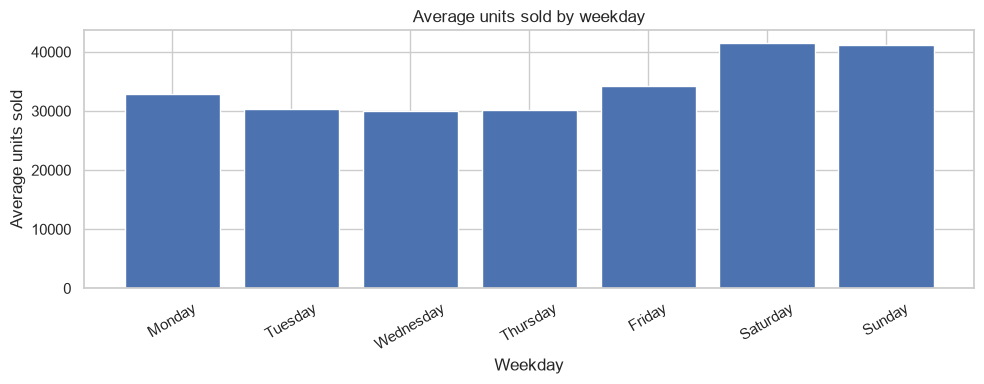

In [5]:
plt.figure(figsize=(10, 4))
plt.bar(weekday_summary["weekday"], weekday_summary["units_sold"])
plt.title("Average units sold by weekday")
plt.xlabel("Weekday")
plt.ylabel("Average units sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Monthly averages

Compare average daily sales by month. Years contribute different numbers of days because the sample starts and ends partway through a year. This is a descriptive comparison, not an isolated estimate of seasonality.

In [6]:
monthly_summary = daily_sales.groupby("month", as_index=False)["units_sold"].mean()
monthly_summary = monthly_summary.sort_values("month")
monthly_summary

,month,units_sold
0,1,33832.348101
1,2,34644.641176
2,3,34339.838710
3,4,34258.683908
4,5,32503.851613
5,6,35001.413333
6,7,35122.419355
7,8,35946.645161
8,9,35479.260000
9,10,34713.477419


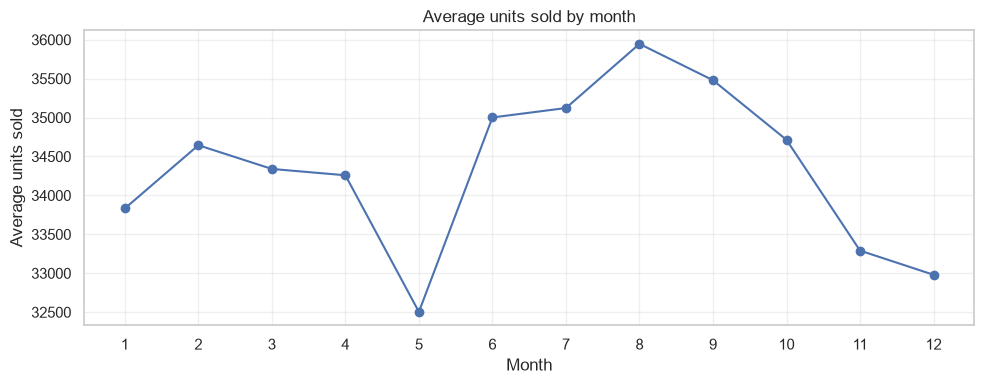

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_summary["month"], monthly_summary["units_sold"], marker="o")
plt.title("Average units sold by month")
plt.xlabel("Month")
plt.ylabel("Average units sold")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Interpretation

Use these averages to identify patterns worth checking at store and item level. They do not by themselves determine an order quantity. Recorded sales may also understate demand when stock is unavailable.